# Práctica 3: Simulador neuronal de CarRacing
## Semana 2: Autoencoder Residual y Elección de la Representación Visual
### Aprendizaje Profundo — Grado en Inteligencia Artificial
**Universidade da Coruña (UDC)**

---

### Información del Grupo de Prácticas
* **Autores:** Xoel Sánchez Dacoba y Sebastián David Moreno Expósito
* **Fecha límite de entrega:** 27 de noviembre de 2026
* **Semana de defensa individual:** 30 de noviembre al 4 de diciembre de 2026
* **Objetivo de la Parte 2:** Evaluar el efecto de las conexiones residuales (de salto) en un autoencoder convolucional, mediante una comparación controlada con los saltos activados y desactivados, y elegir el autoencoder (codificador $E$ y decodificador $D$) que se usará congelado en las partes 3 y 4, dejando precalculados los latentes de cada partición.

---

## Índice de Contenidos
1. [Configuración del Entorno y Reproducibilidad](#sec1)
2. [Datos: misma partición e imágenes de evaluación que la Semana 1](#sec2)
3. [Bloque Residual: diseño y comprobación de dimensiones](#sec3)
4. [Arquitectura del Autoencoder Residual (con interruptor de saltos)](#sec4)
5. [Experimento Controlado: saltos activados frente a desactivados](#sec5)
   * 5.1. Parámetros y flujo del gradiente al inicio (extra)
   * 5.2. Entrenamiento con el mismo presupuesto
   * 5.3. Curvas de pérdida
6. [Evaluación sobre las mismas imágenes de la Semana 1](#sec6)
   * 6.1. Métricas con `visual_metrics` y tiempos
   * 6.2. Reconstrucciones y mapas de error
   * 6.3. Interpretación
7. [Elección del autoencoder, congelación y latentes por partición](#sec7)
8. [Comprobaciones independientes](#sec8)
9. [Conclusiones y puntos para la defensa](#sec9)

<a id='sec1'></a>
## 1. Configuración del Entorno y Reproducibilidad

Usamos las mismas librerías y la **misma semilla global (`SEED = 77`)** que en la Semana 1, de modo que el barajado de los fotogramas de entrenamiento es idéntico al de entonces. Además activamos `tf.config.experimental.enable_op_determinism()`: sin ello, en GPU dos ejecuciones con la misma semilla dan cifras distintas en el tercer decimal, porque cuDNN elige algoritmos no deterministas. Todas las rutas son relativas al directorio del notebook: la carpeta de la entrega se basta sola.

In [ ]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # quita avisos de TensorFlow que no aportan nada aquí
# En nuestra GPU (RTX 5060 Ti) el compilador XLA falla al generar con Triton la multiplicación de
# matrices de la capa latente (1296 -> 24): "Failed to compute symbolic tile". Desactivamos solo ese
# generador; XLA sigue compilando el resto y el resultado numérico es el mismo. Debe ir antes de importar TF.
os.environ['XLA_FLAGS'] = (os.environ.get('XLA_FLAGS', '') + ' --xla_gpu_enable_triton_gemm=false').strip()
import sys
import time
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

CURRENT_DIR = os.path.abspath('')  # módulos locales de la práctica (metric, dataset, carracing48)
if CURRENT_DIR not in sys.path:
    sys.path.insert(0, CURRENT_DIR)

import tensorflow as tf
import keras
from keras import layers, Model

import metric  # visual_metrics: score oficial, SSIM, gradiente y MSE

SEED = 77  # misma semilla que la Semana 1
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
# Operaciones deterministas en GPU: sin esto, cuDNN elige algoritmos no deterministas y dos ejecuciones
# con la misma semilla dan cifras distintas en el tercer decimal.
tf.config.experimental.enable_op_determinism()#Esto es para reproducibilidad extra, que todas las ops se ejecuten en el mismo orden en GPU

os.makedirs('data', exist_ok=True)
os.makedirs('models', exist_ok=True)

gpus = tf.config.list_physical_devices('GPU')
print(f"TensorFlow: {tf.__version__} | Keras: {keras.__version__}")
print(f"Dispositivos GPU detectados: {gpus}")
if not gpus:
    print("AVISO: no se detectó GPU. El entrenamiento se hará en CPU y será más lento.")

I0000 00:00:1795460404.289771  119604 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795460406.469332  119604 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0 | Keras: 3.15.1
Dispositivos GPU detectados: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


<a id='sec2'></a>
## 2. Datos: misma partición e imágenes de evaluación que la Semana 1

> **Enunciado (Semana 2, «Qué reutilizar»):** *"Usa la misma partición y las mismas imágenes de evaluación de la semana 1."*

Cargamos `data/carracing_data.npz`, generado y guardado en la Semana 1:
* **Entrenamiento:** 128 circuitos (`seed=1488`), cada uno con 96 fotogramas y 95 acciones.
* **Validación:** 32 circuitos (`seed=1314`).

Como en la Semana 1, si el fichero no existiera se regeneraría con `dataset.generate_sequences` y las mismas semillas (por eso se incluyen `dataset.py` y `carracing48.py` en la entrega).

Comprobamos además que **ningún circuito de validación aparece en entrenamiento** (regla común 1): comparamos el primer fotograma de cada circuito.

In [ ]:
DATA_FILE = os.path.join('data', 'carracing_data.npz')
TRAIN_SEED, VAL_SEED = 1488, 1314
N_TRAIN_SEQS, N_VAL_SEQS = 128, 32

if os.path.exists(DATA_FILE):
    cached = np.load(DATA_FILE)
    train_frames, train_actions = cached['train_frames'], cached['train_actions']
    val_frames, val_actions = cached['val_frames'], cached['val_actions']
    assert int(cached['train_seed']) == TRAIN_SEED and int(cached['val_seed']) == VAL_SEED
    print(f"Dataset cargado de {DATA_FILE} (semillas {TRAIN_SEED}/{VAL_SEED}).")
else:
    import dataset
    print("No existe el fichero de datos: se regenera con las semillas de la Semana 1...")
    tr = dataset.generate_sequences(seed=TRAIN_SEED, n_sequences=N_TRAIN_SEQS)
    va = dataset.generate_sequences(seed=VAL_SEED, n_sequences=N_VAL_SEQS)
    train_frames, train_actions = tr['frames'], tr['actions']
    val_frames, val_actions = va['frames'], va['actions']
    np.savez_compressed(DATA_FILE, train_frames=train_frames, train_actions=train_actions,
                        val_frames=val_frames, val_actions=val_actions,
                        train_seed=TRAIN_SEED, val_seed=VAL_SEED)

print(f"Train frames:  {train_frames.shape} {train_frames.dtype} | Train actions: {train_actions.shape}")
print(f"Val frames:    {val_frames.shape} {val_frames.dtype} | Val actions:   {val_actions.shape}")

# Ningún circuito compartido entre particiones: huella del primer fotograma de cada circuito
train_keys = {f.tobytes() for f in train_frames[:, 0]}#Tratamos de que 
shared = sum(f.tobytes() in train_keys for f in val_frames[:, 0])
print(f"Circuitos de validacion cuyo primer fotograma aparece en entrenamiento: {shared}")
assert shared == 0

Dataset cargado de data/carracing_data.npz (semillas 1488/1314).
Train frames:  (128, 96, 48, 48, 3) uint8 | Train actions: (128, 95)
Val frames:    (32, 96, 48, 48, 3) uint8 | Val actions:   (32, 95)
Circuitos de validación cuyo primer fotograma aparece en entrenamiento: 0


Preprocesado **idéntico al de la Semana 1**: aplanamos cada partición a fotogramas independientes $(N\cdot 96, 48, 48, 3)$, normalizamos a $[0,1]$ y barajamos solo el entrenamiento con la misma semilla. `X_val` queda en el mismo orden que en la Semana 1, así que los índices `[10, 45, 100, 250, 500]` de los paneles visuales señalan **exactamente las mismas imágenes**.

In [3]:
X_train = train_frames.reshape(-1, 48, 48, 3).astype('float32') / 255.0
X_val   = val_frames.reshape(-1, 48, 48, 3).astype('float32') / 255.0

indices = np.arange(len(X_train))
np.random.shuffle(indices)  # mismo estado de semilla que en la Semana 1
X_train = X_train[indices]

SAMPLE_INDICES = [10, 45, 100, 250, 500]  # mismas imágenes de los paneles de la Semana 1
print(f"X_train: {X_train.shape}  rango [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"X_val:   {X_val.shape}  rango [{X_val.min():.2f}, {X_val.max():.2f}]")

X_train: (12288, 48, 48, 3)  rango [0.00, 0.99]
X_val:   (3072, 48, 48, 3)  rango [0.00, 0.99]


<a id='sec3'></a>
## 3. Bloque Residual: diseño y comprobación de dimensiones

> **Enunciado (tarea 1):** *"Incorpora al menos dos bloques residuales, con dos convoluciones por rama aprendida. Asegura que las dimensiones permiten sumar entrada y salida."*

Seguimos el bloque básico de ResNet del Tema 6 (diapositivas 16, 21 y 24):

$$\mathbf{h} = \mathrm{ReLU}\big(F(\mathbf{x}) + \mathbf{x}\big), \qquad F(\mathbf{x}) = W_b * \mathrm{ReLU}(W_a * \mathbf{x} + b_a) + b_b$$

* **Rama aprendida $F$:** dos convoluciones $3\times 3$ con el mismo número de filtros $C$ que la entrada; la primera con ReLU, la segunda lineal (la ReLU va **después** de la suma).
* **Conexión de salto (atajo):** la entrada $\mathbf{x}$ se suma tal cual (identidad).
* **Dimensiones:** dentro del bloque las convoluciones usan `strides=1` y `padding='same'`, y conservan los $C$ canales. Por tanto $F(\mathbf{x})$ tiene **exactamente** la forma $(H, W, C)$ de $\mathbf{x}$ y la suma `Add` es válida. Los cambios de resolución y de canales se hacen **fuera** de los bloques, con las convoluciones de paso 2 heredadas de la Semana 1.
  * *Alternativa no usada:* el Tema 6 (diapositiva 25) muestra el bloque con proyección, donde el atajo es una convolución $1\times 1$ de paso 2 que ajusta canales y resolución. La descartamos porque añade parámetros que solo existen en la variante con saltos, y entonces la comparación ON/OFF ya no tendría las **mismas ramas** ni el mismo número de parámetros.
* **Interruptor `use_skip`:** con `use_skip=False` el bloque devuelve $\mathrm{ReLU}(F(\mathbf{x}))$ con las **mismas capas y pesos entrenables**; solo desaparece la suma. Así la comparación aísla el efecto del salto (Tema 6, diapositiva 28: *"la incorporación de conexiones residuales no introduce ningún parámetro adicional"*).
* **Sin Batch Normalization:** el Tema 6 (diapositiva 26) la incluye en la variante completa, pero aquí la omitimos para que, frente a la Semana 1 (que tampoco la usaba), el único cambio sea la estructura residual.

In [ ]:
def residual_block(x, filters, name, use_skip=True):
    # Bloque residual: h = ReLU(F(x) + x), F = conv3x3 -> ReLU -> conv3x3.
    # Con use_skip=False: h = ReLU(F(x)) con exactamente las mismas capas.
    if x.shape[-1] != filters:
        raise ValueError(f"{name}: la entrada tiene {x.shape[-1]} canales y la rama {filters} "
                         "el atajo identidad exige que coincidan")
    f = layers.Conv2D(filters, 3, strides=1, padding='same', activation='relu', name=f'{name}_conv_a')(x)
    f = layers.Conv2D(filters, 3, strides=1, padding='same', activation=None, name=f'{name}_conv_b')(f)
    if use_skip:
        f = layers.Add(name=f'{name}_add')([f, x])
    return layers.Activation('relu', name=f'{name}_out')(f)

_x = layers.Input(shape=(12, 12, 48))#Comproación de dimensionalidad entrada->Salida
_probe = Model(_x, residual_block(_x, 48, 'probe'))
_y = _probe(np.zeros((1, 12, 12, 48), dtype='float32'))
print(f"Entrada {(1, 12, 12, 48)} -> salida {tuple(_y.shape)}")
assert tuple(_y.shape) == (1, 12, 12, 48)

Entrada (1, 12, 12, 48) -> salida (1, 12, 12, 48)


<a id='sec4'></a>
## 4. Arquitectura del Autoencoder Residual (con interruptor de saltos)

### Tamaño del espacio latente: $d = 24$
En la Semana 1 se compararon $d=32$ y $d=128$. Para la Semana 2 elegimos un latente **más pequeño y que no sea potencia de 2, $d = 24$** (factor de compresión $6912/24 = 288\times$), por tres motivos:
1. La Semana 1 mostró que pasar de $d=128$ a $d=32$ solo empeora el score de $0.0271$ a $0.0294$: la mayor parte de la información útil cabe ya en un vector pequeño, así que tiene sentido comprobar si se puede comprimir más.
2. En las partes 3 y 4 el predictor temporal (LSTM / transformer) trabaja **en el espacio latente**: con $d=24$ cada paso recibe $[z_t; e_t]$ de pocas dimensiones y la capa de salida $\hat z_{t+1}\in\mathbb{R}^{24}$ es más pequeña, lo que abarata y facilita el aprendizaje de la dinámica.
3. Es un punto intermedio entre $d=32$ (ya estudiado) y una compresión agresiva que borraría los bordillos, donde ya se concentraba el error en la Semana 1.

### Estructura
Mantenemos la «simetría invertida» de la Semana 1 (cuatro reducciones de paso 2: $48\to24\to12\to6\to3$) e insertamos un bloque residual tras cada una de las tres primeras reducciones del codificador y tras cada una de las tres primeras ampliaciones del decodificador: **6 bloques residuales** (12 convoluciones en las ramas), por encima del mínimo de dos que exige el enunciado. Los anchos de canal son $24 \to 48 \to 96 \to 144$.

| Etapa | Codificador $E$ | Forma | Decodificador $D$ | Forma |
|---|---|---|---|---|
| entrada | imagen | $48\times48\times3$ | $z$ | $24$ |
| 1 | `enc_conv1` (s=2) + `enc_res1` | $24\times24\times24$ | `dec_dense` + reshape | $3\times3\times144$ |
| 2 | `enc_conv2` (s=2) + `enc_res2` | $12\times12\times48$ | `dec_deconv1` (s=2) + `dec_res1` | $6\times6\times96$ |
| 3 | `enc_conv3` (s=2) + `enc_res3` | $6\times6\times96$ | `dec_deconv2` (s=2) + `dec_res2` | $12\times12\times48$ |
| 4 | `enc_conv4` (s=2) | $3\times3\times144$ | `dec_deconv3` (s=2) + `dec_res3` | $24\times24\times24$ |
| salida | `latent_code` (Dense lineal) | $24$ | `dec_output` (s=2, sigmoide) | $48\times48\times3$ |

Las salidas de los bloques del codificador (`enc_res1_out`, `enc_res2_out`, `enc_res3_out`) quedan con nombre propio: el anexo C pedirá en las partes 3 y 4 las activaciones de **al menos dos capas convolucionales del codificador congelado, a distintas profundidades y anteriores al latente** para la pérdida perceptual.

In [5]:
LATENT_DIM = 24
CHANNELS = (24, 48, 96, 144)

def build_res_encoder(latent_dim=LATENT_DIM, use_skip=True, name=None):
    # Codificador E: (48, 48, 3) -> (d,)
    c1, c2, c3, c4 = CHANNELS
    inputs = layers.Input(shape=(48, 48, 3), name='encoder_input')
    x = layers.Conv2D(c1, 3, strides=2, padding='same', activation='relu', name='enc_conv1')(inputs)  # 24x24
    x = residual_block(x, c1, 'enc_res1', use_skip)
    x = layers.Conv2D(c2, 3, strides=2, padding='same', activation='relu', name='enc_conv2')(x)       # 12x12
    x = residual_block(x, c2, 'enc_res2', use_skip)
    x = layers.Conv2D(c3, 3, strides=2, padding='same', activation='relu', name='enc_conv3')(x)       # 6x6
    x = residual_block(x, c3, 'enc_res3', use_skip)
    x = layers.Conv2D(c4, 3, strides=2, padding='same', activation='relu', name='enc_conv4')(x)       # 3x3
    x = layers.Flatten(name='enc_flatten')(x)
    latent = layers.Dense(latent_dim, activation=None, name='latent_code')(x)
    tag = 'res' if use_skip else 'noskip'
    return Model(inputs, latent, name=name or f'encoder_{tag}_d{latent_dim}')

def build_res_decoder(latent_dim=LATENT_DIM, use_skip=True, name=None):
    # Decodificador D: (d,) -> (48, 48, 3) en [0, 1]
    c1, c2, c3, c4 = CHANNELS
    inputs = layers.Input(shape=(latent_dim,), name='decoder_input')
    x = layers.Dense(3 * 3 * c4, activation='relu', name='dec_dense')(inputs)
    x = layers.Reshape((3, 3, c4), name='dec_reshape')(x)
    x = layers.Conv2DTranspose(c3, 3, strides=2, padding='same', activation='relu', name='dec_deconv1')(x)  # 6x6
    x = residual_block(x, c3, 'dec_res1', use_skip)
    x = layers.Conv2DTranspose(c2, 3, strides=2, padding='same', activation='relu', name='dec_deconv2')(x)  # 12x12
    x = residual_block(x, c2, 'dec_res2', use_skip)
    x = layers.Conv2DTranspose(c1, 3, strides=2, padding='same', activation='relu', name='dec_deconv3')(x)  # 24x24
    x = residual_block(x, c1, 'dec_res3', use_skip)
    outputs = layers.Conv2DTranspose(3, 3, strides=2, padding='same', activation='sigmoid', name='dec_output')(x)  # 48x48
    tag = 'res' if use_skip else 'noskip'
    return Model(inputs, outputs, name=name or f'decoder_{tag}_d{latent_dim}')

def build_res_autoencoder(use_skip, latent_dim=LATENT_DIM):
    encoder = build_res_encoder(latent_dim, use_skip)
    decoder = build_res_decoder(latent_dim, use_skip)
    ae = Model(encoder.input, decoder(encoder.output),
               name=f"autoencoder_{'res' if use_skip else 'noskip'}_d{latent_dim}")
    return encoder, decoder, ae

In [6]:
enc_s, dec_s, _ = build_res_autoencoder(use_skip=True)
print("=== CODIFICADOR RESIDUAL (d=24) ===")
enc_s.summary(line_length=100)
print("\n=== DECODIFICADOR RESIDUAL (d=24) ===")
dec_s.summary(line_length=100)

=== CODIFICADOR RESIDUAL (d=24) ===


Model: "encoder_res_d24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)  │ (None, 48, 48, 3)       │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_conv1 (Conv2D)          │ (None, 24, 24, 24)      │            672 │ encoder_input[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res1_conv_a (Conv2D)    │ (None, 24, 24, 24)      │          5,208 │ enc_conv1[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res1_conv_b (Conv2D)    │ (None, 24, 24, 24)      │          5,208 │ enc_res1_conv_a[0][0]   │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res1_add (Add)          │ (None, 24, 24, 24)      │              0 │ enc_res1_conv_b[0][0],  │
│                             │                         │                │ enc_conv1[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res1_out (Activation)   │ (None, 24, 24, 24)      │              0 │ enc_res1_add[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_conv2 (Conv2D)          │ (None, 12, 12, 48)      │         10,416 │ enc_res1_out[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res2_conv_a (Conv2D)    │ (None, 12, 12, 48)      │         20,784 │ enc_conv2[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res2_conv_b (Conv2D)    │ (None, 12, 12, 48)      │         20,784 │ enc_res2_conv_a[0][0]   │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res2_add (Add)          │ (None, 12, 12, 48)      │              0 │ enc_res2_conv_b[0][0],  │
│                             │                         │                │ enc_conv2[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res2_out (Activation)   │ (None, 12, 12, 48)      │              0 │ enc_res2_add[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_conv3 (Conv2D)          │ (None, 6, 6, 96)        │         41,568 │ enc_res2_out[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res3_conv_a (Conv2D)    │ (None, 6, 6, 96)        │         83,040 │ enc_conv3[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res3_conv_b (Conv2D)    │ (None, 6, 6, 96)        │         83,040 │ enc_res3_conv_a[0][0]   │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res3_add (Add)          │ (None, 6, 6, 96)        │              0 │ enc_res3_conv_b[0][0],  │
│                             │                         │                │ enc_conv3[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_res3_out (Activation)   │ (None, 6, 6, 96)        │              0 │ enc_res3_add[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ enc_conv4 (Conv2D)          │ (None, 3, 3, 144)       │        124,560 │ enc_res3_out[0][0]      │
├─────────────────────────────┼─────────────────────────┼────

 Total params: 426,408 (1.63 MB)

 Trainable params: 426,408 (1.63 MB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)  │ (None, 24)              │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_dense (Dense)           │ (None, 1296)            │         32,400 │ decoder_input[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_reshape (Reshape)       │ (None, 3, 3, 144)       │              0 │ dec_dense[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_deconv1                 │ (None, 6, 6, 96)        │        124,512 │ dec_reshape[0][0]       │
│ (Conv2DTranspose)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_res1_conv_a (Conv2D)    │ (None, 6, 6, 96)        │         83,040 │ dec_deconv1[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_res1_conv_b (Conv2D)    │ (None, 6, 6, 96)        │         83,040 │ dec_res1_conv_a[0][0]   │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_res1_add (Add)          │ (None, 6, 6, 96)        │              0 │ dec_res1_conv_b[0][0],  │
│                             │                         │                │ dec_deconv1[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_res1_out (Activation)   │ (None, 6, 6, 96)        │              0 │ dec_res1_add[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_deconv2                 │ (None, 12, 12, 48)      │         41,520 │ dec_res1_out[0][0]      │
│ (Conv2DTranspose)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_res2_conv_a (Conv2D)    │ (None, 12, 12, 48)      │         20,784 │ dec_deconv2[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_res2_conv_b (Conv2D)    │ (None, 12, 12, 48)      │         20,784 │ dec_res2_conv_a[0][0]   │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_res2_add (Add)          │ (None, 12, 12, 48)      │              0 │ dec_res2_conv_b[0][0],  │
│                             │                         │                │ dec_deconv2[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_res2_out (Activation)   │ (None, 12, 12, 48)      │              0 │ dec_res2_add[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_deconv3                 │ (None, 24, 24, 24)      │         10,392 │ dec_res2_out[0][0]      │
│ (Conv2DTranspose)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_res3_conv_a (Conv2D)    │ (None, 24, 24, 24)      │          5,208 │ dec_deconv3[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dec_res3_conv_b (Conv2D)    │ (None, 24, 24, 24)      │          5,208 │ dec_res3_conv_a[0][0]   │
├─────────────────────────────┼─────────────────────────┼────

 Total params: 427,539 (1.63 MB)

 Trainable params: 427,539 (1.63 MB)

 Non-trainable params: 0 (0.00 B)

<a id='sec5'></a>
## 5. Experimento Controlado: saltos activados frente a desactivados

> **Enunciado (tarea 2):** *"Compara las conexiones de salto activadas y desactivadas con las mismas ramas, datos y presupuesto. Informa de parámetros, curvas y reconstrucciones."*

Lo único que cambia entre las dos variantes es `use_skip`. Todo lo demás se mantiene **idéntico**:

| Elemento | Valor (igual en ambas) |
|---|---|
| Ramas | mismas capas y mismos nombres (`residual_block`) |
| Inicialización | se fija `keras.utils.set_random_seed(SEED)` antes de construir cada variante → **mismos pesos iniciales** |
| Datos | mismos `X_train` / `X_val` y mismo orden de barajado por época (misma semilla) |
| Presupuesto | **30 épocas** completas, `batch_size=64` |
| Optimizador y pérdida | `Adam(1e-3)` y `mse` (la misma pérdida que la Semana 1) |
| Selección | se conservan los pesos de la época con menor `val_loss` (`EarlyStopping` con paciencia igual al presupuesto, que nunca corta antes y restaura los mejores pesos al final) |

### 5.1. Parámetros y flujo del gradiente al inicio (extra)

Antes de entrenar comprobamos dos cosas:
1. **Parámetros:** deben coincidir exactamente, porque la suma `Add` no tiene pesos.
2. *(Extra, no pedido por el enunciado.)* **Norma del gradiente de la pérdida respecto a los pesos de cada convolución del codificador**, calculada sobre el mismo lote y con los mismos pesos iniciales. El Tema 6 (diapositiva 21) explica que el atajo añade un término $+1$ a la derivada, $\frac{\partial E}{\partial \mathbf{x}} = \frac{\partial E}{\partial \mathbf{h}}\left(\frac{\partial F}{\partial \mathbf{x}} + 1\right)$, de modo que el gradiente llega con más fuerza a las capas más cercanas a la entrada. Con esta medida lo comprobamos sobre nuestra red real.

Parámetros con saltos:    853,947
Parámetros sin saltos:    853,947


,con saltos,sin saltos,cociente con/sin
enc_conv1,1.558e-06,2.332e-08,66.81
enc_res1_conv_a,1.333e-06,2.971e-08,44.86
enc_res1_conv_b,1.551e-06,2.831e-08,54.79
enc_conv2,4.063e-06,2.116e-08,192.04
enc_res2_conv_a,2.291e-06,2.828e-08,81.02
enc_res2_conv_b,2.194e-06,2.900e-08,75.64
enc_conv3,6.623e-06,3.038e-08,218.00
enc_res3_conv_a,3.798e-06,3.066e-08,123.87
enc_res3_conv_b,3.442e-06,3.150e-08,109.29
enc_conv4,9.509e-06,3.152e-08,301.69


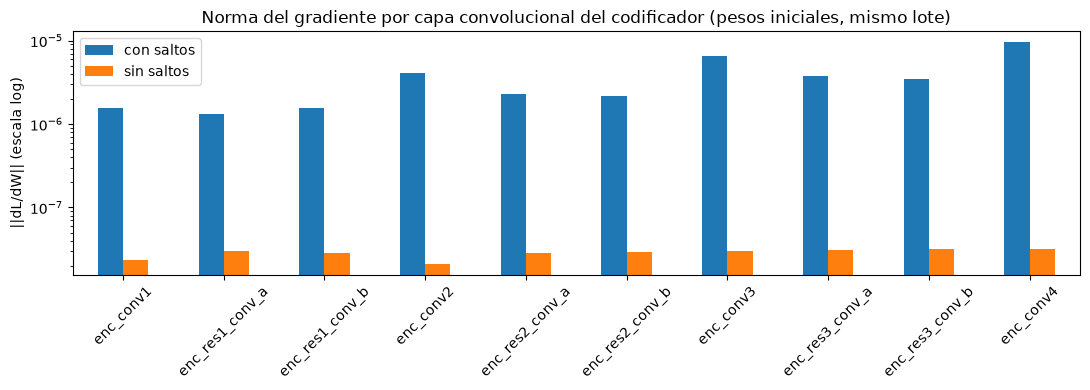

In [7]:
def grad_norms_first_batch(use_skip, batch):
    # Norma L2 del gradiente de la MSE respecto al kernel de cada convolución del codificador (pesos iniciales)
    keras.utils.set_random_seed(SEED)
    enc, dec, ae = build_res_autoencoder(use_skip)
    with tf.GradientTape() as tape:
        rec = ae(batch, training=True)
        loss = tf.reduce_mean(tf.square(batch - rec))
    convs = [l for l in enc.layers if isinstance(l, layers.Conv2D)]
    grads = tape.gradient(loss, [l.kernel for l in convs])
    return ae.count_params(), {l.name: float(tf.norm(g)) for l, g in zip(convs, grads)}

batch0 = X_train[:64]
params_on, gn_on = grad_norms_first_batch(True, batch0)
params_off, gn_off = grad_norms_first_batch(False, batch0)
print(f"Parámetros con saltos:    {params_on:,}")
print(f"Parámetros sin saltos:    {params_off:,}")
assert params_on == params_off

df_grad = pd.DataFrame({'con saltos': gn_on, 'sin saltos': gn_off})
df_grad['cociente con/sin'] = df_grad['con saltos'] / df_grad['sin saltos']
display(df_grad.style.format('{:.3e}', subset=['con saltos', 'sin saltos']).format('{:.2f}', subset=['cociente con/sin']))

ax = df_grad[['con saltos', 'sin saltos']].plot.bar(figsize=(11, 4), logy=True, rot=45)
ax.set_title('Norma del gradiente por capa convolucional del codificador (pesos iniciales, mismo lote)')
ax.set_ylabel('||dL/dW|| (escala log)')
plt.tight_layout(); plt.show()

### 5.2. Entrenamiento con el mismo presupuesto

In [8]:
BATCH_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 1e-3

def train_res_variant(use_skip):
    tag = 'CON saltos' if use_skip else 'SIN saltos'
    print(f"\n{'=' * 60}\n ENTRENANDO AUTOENCODER RESIDUAL d={LATENT_DIM} — {tag}\n{'=' * 60}")
    keras.utils.set_random_seed(SEED)  # mismos pesos iniciales y mismo orden de lotes en ambas variantes
    encoder, decoder, ae = build_res_autoencoder(use_skip)
    ae.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss='mse')
    keep_best = keras.callbacks.EarlyStopping(monitor='val_loss', patience=EPOCHS,
                                              restore_best_weights=True, verbose=1)
    t0 = time.time()
    history = ae.fit(X_train, X_train, validation_data=(X_val, X_val),
                     epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[keep_best], verbose=1)
    elapsed = time.time() - t0
    best_epoch = int(np.argmin(history.history['val_loss'])) + 1
    print(f"Tiempo: {elapsed:.1f} s | mejor época: {best_epoch} | val_loss mínima: {min(history.history['val_loss']):.6f}")
    return {'use_skip': use_skip, 'encoder': encoder, 'decoder': decoder, 'ae': ae,
            'history': history.history, 'time': elapsed, 'best_epoch': best_epoch,
            'params': ae.count_params()}

result_on = train_res_variant(use_skip=True)


 ENTRENANDO AUTOENCODER RESIDUAL d=24 — CON saltos
Epoch 1/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - loss: 0.0149 - val_loss: 0.0041
Epoch 2/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - loss: 0.0030 - val_loss: 0.0025
Epoch 3/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - loss: 0.0023 - val_loss: 0.0021
Epoch 4/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0021 - val_loss: 0.0020
Epoch 5/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 0.0017 - val_loss: 0.0015
Epoch 6/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 0.0014 - val_loss: 0.0014
Epoch 7/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 0.0013 - val_loss: 0.0013
Epoch 8/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 9/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 10/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 11/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - loss: 0.0010 - val_l

In [9]:
result_off = train_res_variant(use_skip=False)


 ENTRENANDO AUTOENCODER RESIDUAL d=24 — SIN saltos
Epoch 1/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - loss: 0.0227 - val_loss: 0.0100
Epoch 2/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - loss: 0.0056 - val_loss: 0.0037
Epoch 3/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - loss: 0.0029 - val_loss: 0.0024
Epoch 4/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - loss: 0.0023 - val_loss: 0.0022
Epoch 5/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 6/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - loss: 0.0021 - val_loss: 0.0020
Epoch 7/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 8/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.0018 - val_loss: 0.0018
Epoch 9/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0018 - val_loss: 0.0018
Epoch 10/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 0.0017 - val_loss: 0.0017
Epoch 11/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 0.0017 - val_l

### 5.3. Curvas de pérdida

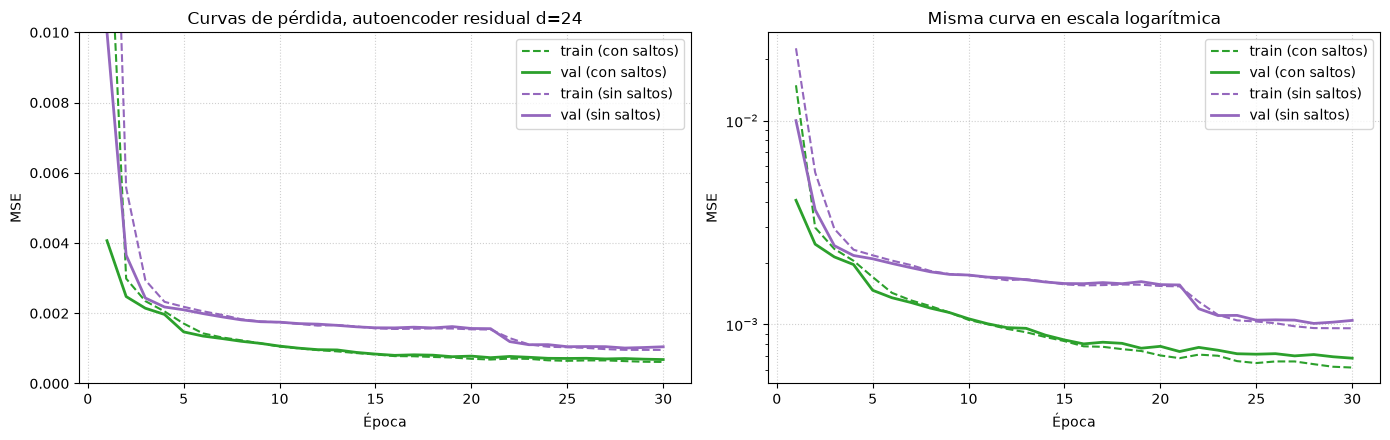

 con saltos: época 1 val=0.004067 | época 5 val=0.001470 | mejor val=0.000682 (época 30) | train final=0.000614
 sin saltos: época 1 val=0.010014 | época 5 val=0.002098 | mejor val=0.001010 (época 28) | train final=0.000957


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, logy in zip(axes, (False, True)):
    for res, color in ((result_on, '#2ca02c'), (result_off, '#9467bd')):
        lab = 'con saltos' if res['use_skip'] else 'sin saltos'
        ax.plot(range(1, EPOCHS + 1), res['history']['loss'], '--', color=color, label=f'train ({lab})')
        ax.plot(range(1, EPOCHS + 1), res['history']['val_loss'], '-', lw=2, color=color, label=f'val ({lab})')
    ax.set_xlabel('Época'); ax.set_ylabel('MSE'); ax.grid(True, ls=':', alpha=.6); ax.legend()
    if logy:
        ax.set_yscale('log'); ax.set_title('Misma curva en escala logarítmica')
    else:
        ax.set_ylim(0, 0.01); ax.set_title(f'Curvas de pérdida, autoencoder residual d={LATENT_DIM}')
plt.tight_layout(); plt.show()

for res in (result_on, result_off):
    h = res['history']
    lab = 'con saltos' if res['use_skip'] else 'sin saltos'
    print(f"{lab:>11}: época 1 val={h['val_loss'][0]:.6f} | época 5 val={h['val_loss'][4]:.6f} | "
          f"mejor val={min(h['val_loss']):.6f} (época {res['best_epoch']}) | train final={h['loss'][-1]:.6f}")

<a id='sec6'></a>
## 6. Evaluación sobre las mismas imágenes de la Semana 1

> **Enunciado (función proporcionada):** *"usa `visual_metrics(originales, reconstrucciones)` de `metric` para comparar ambos autoencoders sobre las mismas imágenes guardadas en la parte 1."*

Evaluamos los **cuatro candidatos** sobre los 3072 fotogramas de validación (las mismas imágenes de la Semana 1):
* los dos autoencoders residuales de esta semana ($d=24$, saltos activados y desactivados);
* los dos autoencoders planos de la Semana 1 ($d=32$ y $d=128$), cargados de `models/` (su `encoder` y `decoder` guardados por separado).

Además medimos el **tiempo de inferencia** de $D(E(x))$ sobre todo el conjunto de validación (media de 3 repeticiones tras un calentamiento), porque en las partes 3–5 el codificador y el decodificador se ejecutan en cada paso.

In [ ]:
def load_week1(d):
    enc = keras.models.load_model(os.path.join('models', f'encoder_d{d}.keras'))
    dec = keras.models.load_model(os.path.join('models', f'decoder_d{d}.keras'))
    return enc, dec

candidates = {
    f'Residual d={LATENT_DIM} (con saltos)': (result_on['encoder'], result_on['decoder'], result_on['time']),
    f'Residual d={LATENT_DIM} (sin saltos)': (result_off['encoder'], result_off['decoder'], result_off['time']),
}
for d, t_train in ((32, 51.1), (128, 48.1)):  # tiempos de entrenamiento medidos en la Semana 1
    enc, dec = load_week1(d)
    candidates[f'Plano Semana 1 d={d}'] = (enc, dec, t_train)

def reconstruct(enc, dec, X):
    z = enc.predict(X, batch_size=256, verbose=0)
    return np.clip(dec.predict(z, batch_size=256, verbose=0), 0.0, 1.0)

def time_inference(enc, dec, X, reps=3):
    reconstruct(enc, dec, X[:256])  # calentamiento (compilación del grafo)
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); reconstruct(enc, dec, X); ts.append(time.perf_counter() - t0)
    return 1000 * np.mean(ts) / len(X)

recs, rows = {}, []
for name, (enc, dec, t_train) in candidates.items():
    recs[name] = reconstruct(enc, dec, X_val)
    m = metric.visual_metrics(X_val, recs[name])
    d = enc.output.shape[-1]
    rows.append({'Modelo': name, 'Latente (d)': d, 'Compresión': f"{48 * 48 * 3 / d:.0f}x",
                 'Parámetros E+D': enc.count_params() + dec.count_params(),
                 'Entreno (s)': round(t_train, 1), 'Inferencia (ms/img)': time_inference(enc, dec, X_val),
                 'Val MSE': m['mse'], 'Val SSIM': m['ssim'], 'Val Gradient': m['gradient'],
                 'Kaggle Score': m['score']})

df_results = pd.DataFrame(rows).set_index('Modelo')
display(df_results.style.format({'Val MSE': '{:.6f}', 'Val SSIM': '{:.4f}', 'Val Gradient': '{:.6f}',
                                 'Kaggle Score': '{:.5f}', 'Inferencia (ms/img)': '{:.4f}', 'Entreno (s)': '{:.1f}',
                                 'Parámetros E+D': '{:,}'})
                          .highlight_min(subset=['Val MSE', 'Val Gradient', 'Kaggle Score'], color='#c7e9c0')
                          .highlight_max(subset=['Val SSIM'], color='#c7e9c0'))

,Latente (d),Compresión,Parámetros E+D,Entreno (s),Inferencia (ms/img),Val MSE,Val SSIM,Val Gradient,Kaggle Score
Modelo,,,,,,,,,
Residual d=24 (con saltos),24,288x,"853,947",199.8,0.1325,0.000682,0.9422,0.003968,0.02393
Residual d=24 (sin saltos),24,288x,"853,947",181.9,0.1238,0.001010,0.9160,0.003933,0.03440
Plano Semana 1 d=32,32,216x,"926,371",51.1,0.1256,0.000693,0.9286,0.004266,0.02941
Plano Semana 1 d=128,128,54x,"1,368,835",48.1,0.1293,0.000658,0.9345,0.004306,0.02707


Como referencia de escala, repetimos la **cota sin entrenamiento de la Semana 1** (repetir la última imagen 24 pasos; score $0.1009$). No es comparable con una reconstrucción (reconstruir la imagen que se ve es más fácil que predecir la siguiente), pero indica que todo error de reconstrucción del autoencoder **se sumará** al error de predicción en las partes 3 y 4: cuanto menor sea aquí, más margen deja al predictor.

### 6.2. Reconstrucciones y mapas de error

Mismos cinco fotogramas de validación que en la Semana 1. El mapa de error es $|x - \tilde x|$ promediado en los canales RGB, con la misma escala de color ($[0, 0.3]$) en todas las columnas.

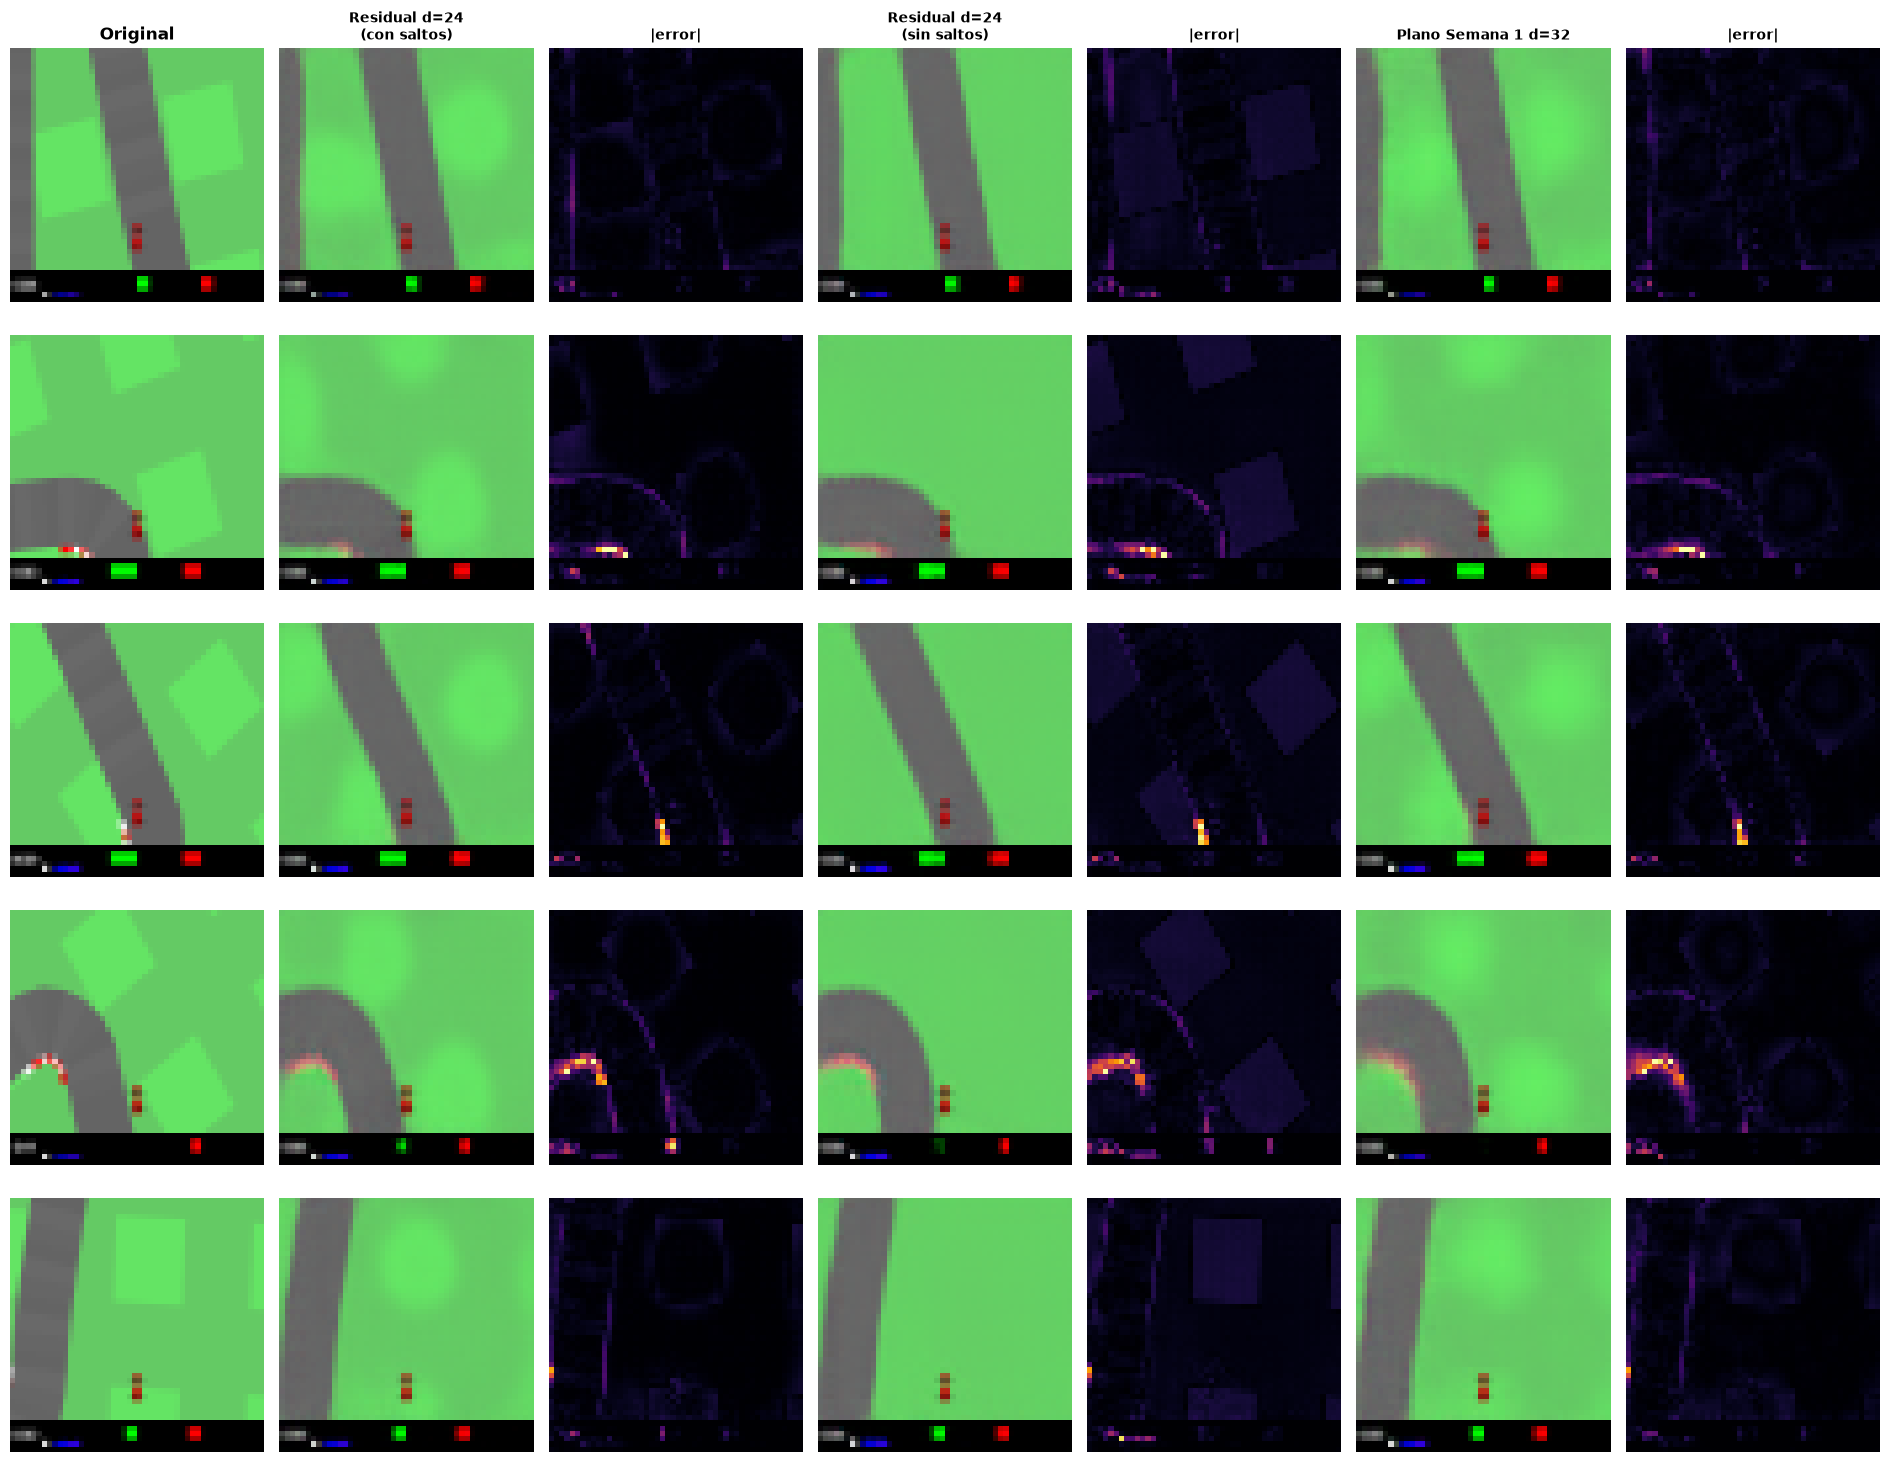

In [12]:
show = [f'Residual d={LATENT_DIM} (con saltos)', f'Residual d={LATENT_DIM} (sin saltos)', 'Plano Semana 1 d=32']
fig, axes = plt.subplots(len(SAMPLE_INDICES), 1 + 2 * len(show), figsize=(19, 3 * len(SAMPLE_INDICES)))
for row, idx in enumerate(SAMPLE_INDICES):
    orig = X_val[idx]
    axes[row, 0].imshow(orig)
    if row == 0:
        axes[row, 0].set_title('Original', fontweight='bold')
    for k, name in enumerate(show):
        rec = recs[name][idx]
        err = np.mean(np.abs(orig - rec), axis=-1)
        axes[row, 1 + 2 * k].imshow(rec)
        axes[row, 2 + 2 * k].imshow(err, cmap='inferno', vmin=0, vmax=0.3)
        if row == 0:
            axes[row, 1 + 2 * k].set_title(name.replace(' (', '\n('), fontsize=10, fontweight='bold')
            axes[row, 2 + 2 * k].set_title('|error|', fontsize=10, fontweight='bold')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout(); plt.show()

Para ver **dónde** se pierde la información en todo el conjunto (no solo en cinco ejemplos), promediamos el mapa de error sobre los 3072 fotogramas de validación. Mostramos también los fotogramas **mejor y peor** reconstruidos por el autoencoder residual con saltos (por MSE individual): el enunciado pide incluir aciertos y fallos.

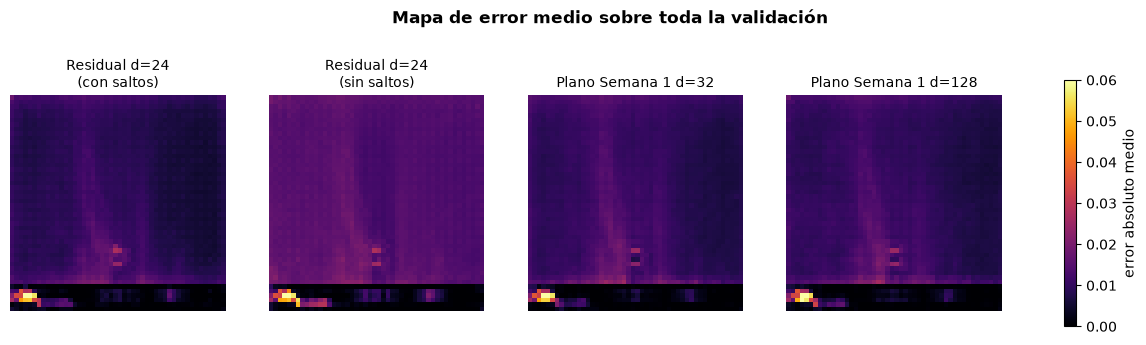

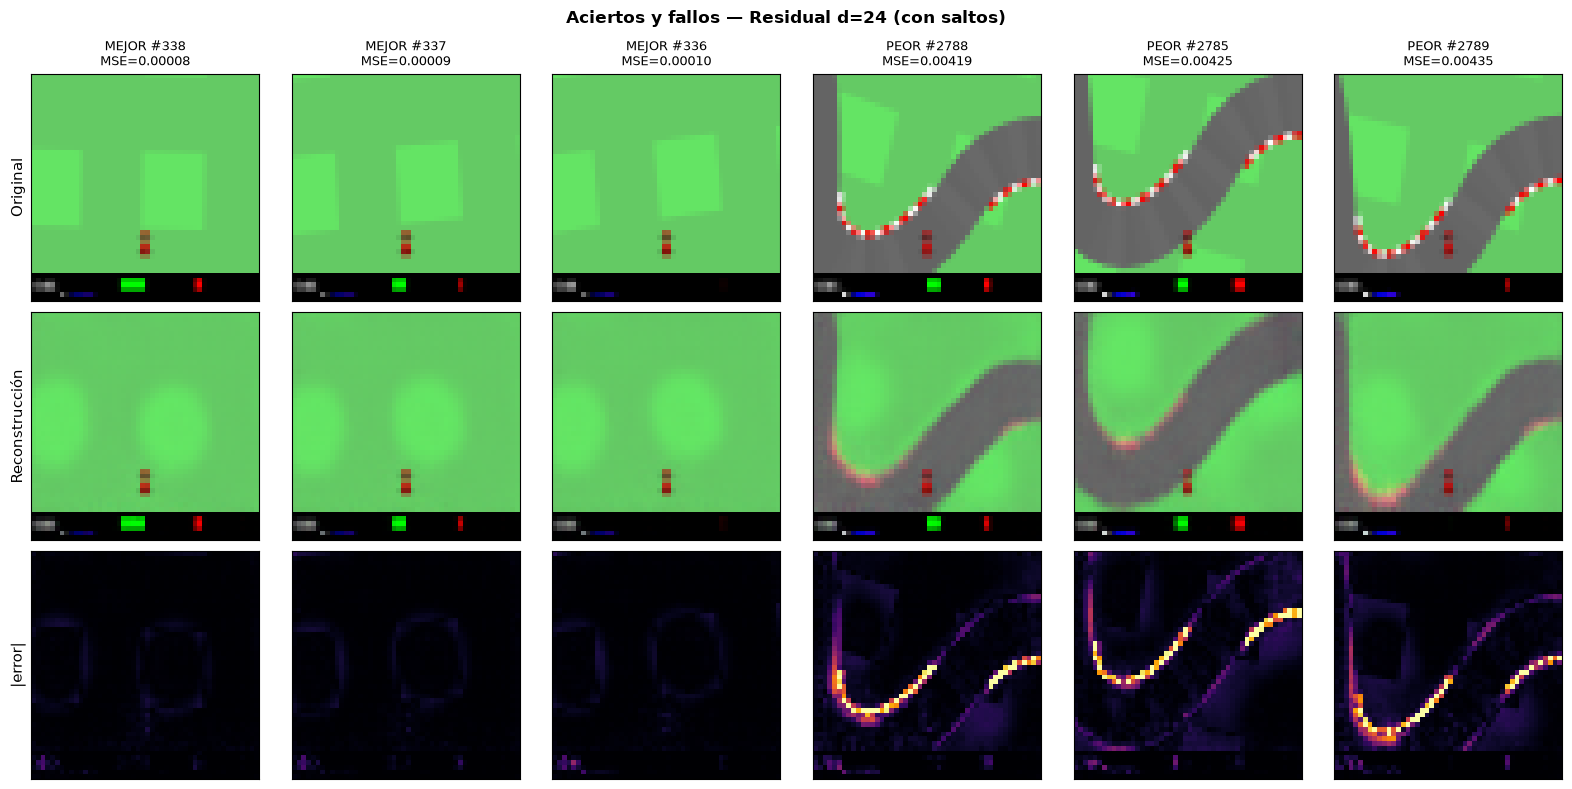

In [13]:
fig, axes = plt.subplots(1, len(recs), figsize=(4 * len(recs), 4))
for ax, (name, rec) in zip(axes, recs.items()):
    im = ax.imshow(np.mean(np.abs(X_val - rec), axis=(0, -1)), cmap='inferno', vmin=0, vmax=0.06)
    ax.set_title(name.replace(' (', '\n('), fontsize=10); ax.axis('off')
fig.colorbar(im, ax=axes, shrink=0.8, label='error absoluto medio')
plt.suptitle('Mapa de error medio sobre toda la validación', fontweight='bold')
plt.show()

best_name = f'Residual d={LATENT_DIM} (con saltos)'
per_img = np.mean((X_val - recs[best_name]) ** 2, axis=(1, 2, 3))
order = np.argsort(per_img)
picks = list(order[:3]) + list(order[-3:])
fig, axes = plt.subplots(3, 6, figsize=(16, 8))
for c, idx in enumerate(picks):
    axes[0, c].imshow(X_val[idx]); axes[1, c].imshow(recs[best_name][idx])
    axes[2, c].imshow(np.mean(np.abs(X_val[idx] - recs[best_name][idx]), axis=-1), cmap='inferno', vmin=0, vmax=0.3)
    axes[0, c].set_title(f"{'MEJOR' if c < 3 else 'PEOR'} #{idx}\nMSE={per_img[idx]:.5f}", fontsize=9)
for r, lab in enumerate(['Original', 'Reconstrucción', '|error|']):
    axes[r, 0].set_ylabel(lab, fontsize=11)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f'Aciertos y fallos — {best_name}', fontweight='bold'); plt.tight_layout(); plt.show()

### 6.3. Interpretación

La celda siguiente calcula las diferencias relativas que se comentan en el análisis, para que las cifras del texto salgan del propio experimento.

In [14]:
r_on, r_off = df_results.loc[f'Residual d={LATENT_DIM} (con saltos)'], df_results.loc[f'Residual d={LATENT_DIM} (sin saltos)']
r32, r128 = df_results.loc['Plano Semana 1 d=32'], df_results.loc['Plano Semana 1 d=128']
pct = lambda a, b: 100 * (a - b) / b
print("Con saltos frente a sin saltos (mismo d=24, mismos parámetros):")
for k in ('Val MSE', 'Val SSIM', 'Val Gradient', 'Kaggle Score'):
    print(f"  {k:<13}: {r_on[k]:.6f} vs {r_off[k]:.6f}  ({pct(r_on[k], r_off[k]):+.1f} %)")
print(f"  Época del mínimo de val_loss: {result_on['best_epoch']} vs {result_off['best_epoch']}")
print(f"  Tiempo de entrenamiento: {result_on['time']:.1f} s vs {result_off['time']:.1f} s")
print("\nResidual con saltos (d=24) frente a los planos de la Semana 1:")
for ref_name, ref in (('d=32', r32), ('d=128', r128)):
    print(f"  vs {ref_name}: score {pct(r_on['Kaggle Score'], ref['Kaggle Score']):+.1f} %, "
          f"MSE {pct(r_on['Val MSE'], ref['Val MSE']):+.1f} %, "
          f"parámetros {pct(r_on['Parámetros E+D'], ref['Parámetros E+D']):+.1f} %")

Con saltos frente a sin saltos (mismo d=24, mismos parámetros):
  Val MSE      : 0.000682 vs 0.001010  (-32.5 %)
  Val SSIM     : 0.942163 vs 0.915964  (+2.9 %)
  Val Gradient : 0.003968 vs 0.003933  (+0.9 %)
  Kaggle Score : 0.023928 vs 0.034401  (-30.4 %)
  Época del mínimo de val_loss: 30 vs 28
  Tiempo de entrenamiento: 199.8 s vs 181.9 s

Residual con saltos (d=24) frente a los planos de la Semana 1:
  vs d=32: score -18.6 %, MSE -1.6 %, parámetros -7.8 %
  vs d=128: score -11.6 %, MSE +3.7 %, parámetros -37.6 %


**Análisis de los resultados obtenidos:**

1. **Efecto de las conexiones de salto** (comparación controlada: mismo $d=24$, mismas ramas y mismos 853 947 parámetros):
   * **Reconstrucción:** con saltos, el MSE de validación baja de $0.001010$ a $0.000682$ ($-32.5\,\%$), el SSIM sube de $0.9160$ a $0.9422$ y el Kaggle Score mejora de $0.0344$ a $0.0239$ ($-30.4\,\%$). Los parámetros, los datos, la inicialización y el presupuesto son idénticos, así que la diferencia se debe solo a la suma $F(\mathbf{x}) + \mathbf{x}$.
   * **Optimización:**
     * La variante sin saltos arranca mucho peor (val MSE en la época 1: $0.0100$ frente a $0.0041$) y se estanca en torno a $10^{-3}$.
     * La residual sigue bajando hasta $\approx 7\cdot 10^{-4}$.
     * El error de **entrenamiento** de la red sin saltos también es mayor ($0.00096$ frente a $0.00061$ en la última época), así que no es sobreajuste: es el **problema de degradación** del Tema 6 (diapositiva 10). Una red plana más profunda (aquí 16 convoluciones frente a las 8 de la Semana 1) es más difícil de optimizar.
   * **Gradiente al inicio** (extra, sección 5.1): con los mismos pesos iniciales, la norma del gradiente en las convoluciones del codificador es entre $45$ y $300$ veces mayor con saltos. Sin saltos, el gradiente que llega a `enc_conv1` es del orden de $10^{-8}$. Es la comprobación empírica del término $+1$ de la diapositiva 21: el atajo deja pasar el gradiente sin atravesar las activaciones de la rama.
   * **Bordes:**
     * El error de gradiente $G$ es prácticamente igual en las dos variantes ($0.00397$ con saltos frente a $0.00393$ sin saltos). Toda la mejora del score viene del SSIM, es decir, de la estructura local.
     * En los paneles se ve dónde está esa diferencia: la red sin saltos borra por completo los cuadrados de hierba más clara (los pinta del verde de fondo), mientras que la residual los conserva como manchas difusas.
2. **Comparación con los autoencoders planos de la Semana 1** (no es una comparación controlada: cambian $d$, la profundidad y el número de épocas, 30 frente a 20):
   * El residual con $d=24$ obtiene el **mejor score de los cuatro**: $0.0239$, frente a $0.0294$ del plano $d=32$ y $0.0271$ del plano $d=128$. Lo hace con un latente $5.3$ veces más pequeño que el del $d=128$ y con un $37.6\,\%$ menos de parámetros.
   * En MSE el plano $d=128$ sigue siendo algo mejor ($0.000658$ frente a $0.000682$). La ventaja del residual está en el SSIM ($0.9422$ frente a $0.9345$), que es lo que más pesa en la métrica de Kaggle.
3. **Dónde se pierde la información** (mapas de error y peores casos):
   * En **todos** los modelos el error se concentra en los **bordillos rojos y blancos** de las curvas: el patrón alterno de 1–2 píxeles se reconstruye como una franja rosa uniforme.
   * Los tres peores fotogramas del residual son curvas en S con bordillos (MSE $\approx 0.0042$–$0.0044$, unas 50 veces el de los mejores).
   * Los mejores fotogramas son tramos de solo hierba con el coche ($\text{MSE}\approx 10^{-4}$).
   * La barra inferior (indicadores de velocidad y giro) concentra error en su esquina izquierda en todos los modelos.
   * El coche, siempre en la misma posición en el centro inferior, se reconstruye bien.
4. **Coste:**
   * En esta ejecución, entrenar costó $199.8$ s con saltos y $181.9$ s sin saltos.
   * Esa diferencia no es significativa: en otra ejecución idéntica salieron $168.9$ s y $169.5$ s. El tiempo de reloj varía entre ejecuciones aunque las métricas sean exactamente las mismas, y la suma no tiene parámetros ni un coste apreciable.
   * Los tiempos son unas $2.5$ veces mayores que sin determinismo ($\approx 70$ s), porque `enable_op_determinism` obliga a usar algoritmos de cuDNN deterministas, que son más lentos.
   * No son comparables con los $\approx 50$ s de la Semana 1, que se entrenó sin determinismo y en otra GPU(aunque peor).
   * La inferencia de $D(E(x))$ está en torno a $0.12$–$0.13$ ms por imagen para todos los candidatos.
5. **Reproducibilidad:** con `enable_op_determinism` el notebook es determinista en la misma máquina. Lo comprobamos ejecutándolo dos veces desde cero en carpetas distintas: los cuatro scores coinciden en todas las cifras (por ejemplo, $0.023928385568$ con saltos en ambas ejecuciones). Sin determinismo, una ejecución anterior dio $0.0250$ con saltos frente a $0.0348$ sin saltos; las cifras se movían en el tercer decimal, pero la conclusión y el modelo elegido eran los mismos. En otra GPU o con otra versión de cuDNN las cifras pueden diferir ligeramente.

<a id='sec7'></a>
## 7. Elección del autoencoder, congelación y latentes por partición

> **Enunciado (tarea 3):** *"Elige el autoencoder que usarás en las partes 3 y 4. Congélalo y precalcula los latentes de cada partición por separado."*
> **Apoyo en Keras:** *"API funcional, `Add` y `trainable=False`; recompila el modelo de entrenamiento tras cambiar qué capas son entrenables."*

**Criterio de elección (fijado antes de mirar los resultados):**
1. Solo se usa **validación** (nunca los datos de Kaggle).
2. Criterio principal: **menor Kaggle Score** en validación, porque es la métrica con la que se evaluarán las imágenes decodificadas en las partes 3–5.
3. Si dos candidatos quedan a menos de un 3 % en score, se prefiere el de **latente más pequeño**, porque es el espacio en el que trabajará el predictor temporal.

In [15]:
scores = df_results['Kaggle Score']
best_score = scores.min()
tied = df_results[scores <= best_score * 1.03]
chosen_name = tied.sort_values(['Latente (d)', 'Kaggle Score']).index[0]
print("Candidatos ordenados por score:")
print(scores.sort_values().to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nEmpatados (≤ 3 % del mejor): {list(tied.index)}")
print(f"ELEGIDO: {chosen_name}")

chosen_encoder, chosen_decoder, _ = candidates[chosen_name]
chosen_d = int(chosen_encoder.output.shape[-1])

Candidatos ordenados por score:
Modelo
Residual d=24 (con saltos)   0.02393
Plano Semana 1 d=128         0.02707
Plano Semana 1 d=32          0.02941
Residual d=24 (sin saltos)   0.03440

Empatados (≤ 3 % del mejor): ['Residual d=24 (con saltos)']
ELEGIDO: Residual d=24 (con saltos)


**Congelación.** Ponemos `trainable=False` en el codificador y en el decodificador elegidos. En Keras, al marcar un modelo como no entrenable, todas sus capas pasan a no entrenables y sus pesos se mueven a `non_trainable_weights`; el atributo se guarda en el fichero `.keras`, así que al cargarlo en las partes 3 y 4 seguirán congelados.

Como indica el enunciado, cualquier modelo de entrenamiento que contenga estas piezas debe **recompilarse** después de cambiar `trainable`, porque `compile()` fija qué pesos actualiza el optimizador. Lo demostramos con un autoencoder compuesto de las piezas congeladas: tras recompilar y ejecutar `fit` una época, los pesos no cambian (Keras avisa con *"The model does not have any trainable weights"*, que es justo lo que queremos comprobar).

Recordatorio para las partes 3 y 4 (anexo C): *congelar no es cortar el gradiente*. `trainable=False` impide actualizar los pesos de $D$ y del extractor, pero el gradiente de la pérdida perceptual **sí** los atravesará hasta el predictor; además se llamarán con `training=False`.

In [ ]:
chosen_encoder.trainable = False
chosen_decoder.trainable = False

frozen_ae = Model(chosen_encoder.input, chosen_decoder(chosen_encoder.output), name='autoencoder_elegido_congelado')
frozen_ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')  # recompilación tras cambiar trainable
before = [w.copy() for w in frozen_ae.get_weights()]
frozen_ae.fit(X_train[:512], X_train[:512], epochs=1, batch_size=64, verbose=0)
unchanged = all(np.array_equal(a, b) for a, b in zip(before, frozen_ae.get_weights()))
print(f"Pesos entrenables tras congelar: {len(frozen_ae.trainable_weights)} | "
      f"no entrenables: {len(frozen_ae.non_trainable_weights)}")
print(f"¿Los pesos siguen idénticos tras un fit? {unchanged}")
assert unchanged and len(frozen_ae.trainable_weights) == 0

ENC_PATH = os.path.join('models', 'encoder_elegido.keras')
DEC_PATH = os.path.join('models', 'decoder_elegido.keras')
chosen_encoder.save(ENC_PATH)
chosen_decoder.save(DEC_PATH)

for res in (result_on, result_off):# También se guardan los cuatro modelos residuales entrenados esta semana (para reproducir la comparación)
    res['encoder'].save(os.path.join('models', f"{res['encoder'].name}.keras"))
    res['decoder'].save(os.path.join('models', f"{res['decoder'].name}.keras"))

with open(os.path.join('models', 'eleccion.json'), 'w', encoding='utf-8') as fh:
    json.dump({'modelo_elegido': chosen_name, 'latent_dim': chosen_d,
               'encoder': 'models/encoder_elegido.keras', 'decoder': 'models/decoder_elegido.keras',
               'criterio': 'menor Kaggle Score en validacion; a menos de un 3 % se prefiere el latente menor',
               'scores_validacion': {k: float(v) for k, v in scores.items()},
               'capas_perceptuales_disponibles': [l.name for l in chosen_encoder.layers
                                                  if isinstance(l, (layers.Conv2D, layers.Activation))]},
              fh, ensure_ascii=False, indent=2)

for f in sorted(os.listdir('models')):
    print(f"  models/{f:<32} {os.path.getsize(os.path.join('models', f)) / 1024:8.1f} KB")

<venv>/site-packages/keras/src/backend/tensorflow/trainer.py:86: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Pesos entrenables tras congelar: 0 | no entrenables: 44
¿Los pesos siguen idénticos tras un fit? True
  models/decoder_d128.keras                 2708.0 KB
  models/decoder_d32.keras                  1844.0 KB
  models/decoder_elegido.keras              1738.7 KB
  models/decoder_noskip_d24.keras           1731.2 KB
  models/decoder_res_d24.keras              1738.7 KB
  models/eleccion.json                         0.8 KB
  models/encoder_d128.keras                 2700.5 KB
  models/encoder_d32.keras                  1836.1 KB
  models/encoder_elegido.keras              1734.2 KB
  models/encoder_noskip_d24.keras           1726.8 KB
  models/encoder_res_d24.keras              1734.2 KB


**Latentes por partición.** Codificamos cada partición **por separado** y conservamos la estructura por circuito $(N, 96, d)$, sin aplanar ni barajar, junto con sus acciones $(N, 95)$. Así, en la parte 3 el ventaneo se aplicará directamente sobre los latentes con la misma alineación que las imágenes ($z_j = E(x_j)$ y la acción $a_j$ lleva de $x_j$ a $x_{j+1}$), y ninguna ventana mezclará circuitos ni particiones.

In [17]:
def encode_partition(frames_uint8, encoder):
    n, t = frames_uint8.shape[:2]
    x = frames_uint8.reshape(-1, 48, 48, 3).astype('float32') / 255.0
    z = encoder.predict(x, batch_size=512, verbose=0)
    return z.reshape(n, t, -1).astype('float32')

t0 = time.time()
z_train = encode_partition(train_frames, chosen_encoder)
z_val = encode_partition(val_frames, chosen_encoder)
print(f"Latentes calculados en {time.time() - t0:.1f} s")

LAT_TRAIN = os.path.join('data', 'latentes_train.npz')
LAT_VAL = os.path.join('data', 'latentes_val.npz')
np.savez_compressed(LAT_TRAIN, latents=z_train, actions=train_actions, seed=TRAIN_SEED,
                    encoder='models/encoder_elegido.keras')
np.savez_compressed(LAT_VAL, latents=z_val, actions=val_actions, seed=VAL_SEED,
                    encoder='models/encoder_elegido.keras')
print(f"{LAT_TRAIN}: latents {z_train.shape}, actions {train_actions.shape}")
print(f"{LAT_VAL}:   latents {z_val.shape}, actions {val_actions.shape}")
print(f"Estadísticos de z_train: media {z_train.mean():.3f}, desviación {z_train.std():.3f}, "
      f"rango [{z_train.min():.2f}, {z_train.max():.2f}]")

Latentes calculados en 2.0 s
data/latentes_train.npz: latents (128, 96, 24), actions (128, 95)
data/latentes_val.npz:   latents (32, 96, 24), actions (32, 95)
Estadísticos de z_train: media -0.098, desviación 1.621, rango [-15.63, 13.25]


Visualizamos la trayectoria de las primeras componentes del latente a lo largo de un circuito de validación, con la acción ejecutada en cada paso. Es lo que verá el predictor temporal de la parte 3: una serie $z_0, z_1, \dots, z_{95}$ que cambia según las acciones.

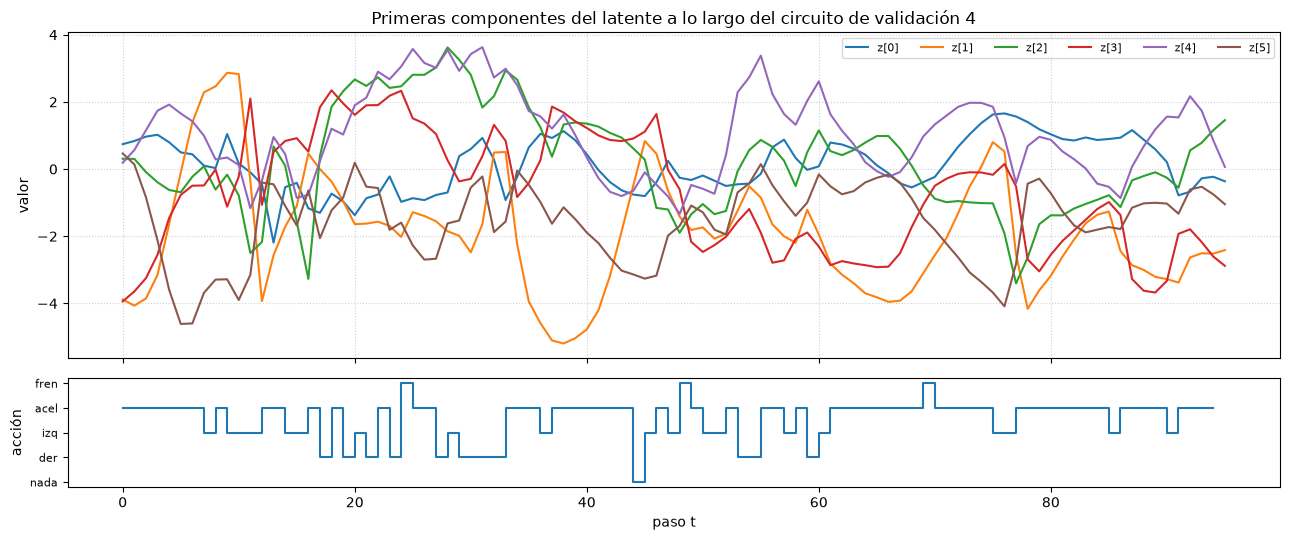

In [18]:
seq = 4  # mismo circuito que se inspeccionó en la Semana 1
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
for k in range(min(6, chosen_d)):
    ax1.plot(z_val[seq, :, k], label=f'z[{k}]')
ax1.set_ylabel('valor'); ax1.legend(ncol=6, fontsize=8); ax1.grid(True, ls=':', alpha=.6)
ax1.set_title(f'Primeras componentes del latente a lo largo del circuito de validación {seq}')
ax2.step(range(95), val_actions[seq], where='post')
ax2.set_yticks(range(5)); ax2.set_yticklabels(['nada', 'der', 'izq', 'acel', 'fren'], fontsize=8)
ax2.set_xlabel('paso t'); ax2.set_ylabel('acción')
plt.tight_layout(); plt.show()

<a id='sec8'></a>
## 8. Comprobaciones independientes

Verificamos lo guardado con **otro camino de código** que no reutiliza las funciones anteriores:
1. **Recarga desde disco** de `encoder_elegido.keras` y `decoder_elegido.keras`: siguen congelados (0 pesos entrenables).
2. **Latentes:** se recalculan con llamadas directas `model(x, training=False)` por lotes (sin `predict` ni `encode_partition`) y se comparan con los guardados en `latentes_val.npz`. La tolerancia es relativa ($10^{-3}$) porque en GPU TensorFlow multiplica en TF32 (unas 3 cifras decimales de precisión).
3. **Métrica:** el MSE de reconstrucción del modelo recargado se calcula a mano con NumPy y se compara con el `mse` de `metric.visual_metrics` y con el de la tabla de la sección 6.
4. **SSIM:** para unas imágenes se compara `visual_metrics` con una llamada directa a `skimage.metrics.structural_similarity` con los parámetros del anexo D.
5. **Alineación:** los latentes guardados conservan la forma por circuito $(N, 96, d)$ y las acciones $(N, 95)$ coinciden con las del dataset.

In [19]:
from skimage.metrics import structural_similarity

enc_l = keras.models.load_model(ENC_PATH)
dec_l = keras.models.load_model(DEC_PATH)
print(f"1) Pesos entrenables tras recargar: encoder={len(enc_l.trainable_weights)}, decoder={len(dec_l.trainable_weights)}")
assert len(enc_l.trainable_weights) == 0 and len(dec_l.trainable_weights) == 0

saved = np.load(LAT_VAL)
xv = val_frames.reshape(-1, 48, 48, 3).astype('float32') / 255.0
z_direct = np.concatenate([enc_l(xv[i:i + 256], training=False).numpy() for i in range(0, len(xv), 256)])
diff_z = np.max(np.abs(z_direct.reshape(saved['latents'].shape) - saved['latents']))
rel_z = diff_z / np.max(np.abs(saved['latents']))
print(f"2) Máxima diferencia entre latentes recalculados y guardados: {diff_z:.2e} "
      f"(relativa al mayor |z|: {rel_z:.1e})")
# Tolerancia relativa 1e-3: en GPU, TensorFlow usa TF32 en convoluciones y productos de matrices
# (mantisa de 10 bits, ~3 cifras decimales), y predict() y la llamada directa agrupan las operaciones
# en lotes distintos, así que los resultados coinciden solo hasta esa precisión.
assert rel_z < 1e-3

rec_direct = np.concatenate([dec_l(z_direct[i:i + 256], training=False).numpy() for i in range(0, len(z_direct), 256)])
rec_direct = np.clip(rec_direct, 0, 1)
mse_numpy = float(np.mean((xv.astype(np.float64) - rec_direct.astype(np.float64)) ** 2))
mse_metric = metric.visual_metrics(xv, rec_direct)['mse']
mse_table = df_results.loc[chosen_name, 'Val MSE']
print(f"3) MSE NumPy={mse_numpy:.7f} | metric={mse_metric:.7f} | tabla sección 6={mse_table:.7f}")
assert abs(mse_numpy - mse_metric) < 1e-9 and abs(mse_numpy - mse_table) / mse_table < 5e-3  # TF32: misma tolerancia relativa que arriba

idx = SAMPLE_INDICES
ssim_ref = np.mean([structural_similarity(xv[i].astype(np.float64), rec_direct[i].astype(np.float64),
                                          data_range=1.0, channel_axis=-1, win_size=7,
                                          gaussian_weights=False, use_sample_covariance=True) for i in idx])
ssim_metric = metric.visual_metrics(xv[idx], rec_direct[idx])['ssim']
print(f"4) SSIM skimage directo={ssim_ref:.6f} | visual_metrics={ssim_metric:.6f}")
assert abs(ssim_ref - ssim_metric) < 1e-9

print(f"5) Formas guardadas: latents {saved['latents'].shape}, actions {saved['actions'].shape}")
assert saved['latents'].shape == (val_frames.shape[0], val_frames.shape[1], chosen_d)
assert np.array_equal(saved['actions'], val_actions)
assert np.load(LAT_TRAIN)['latents'].shape == (train_frames.shape[0], train_frames.shape[1], chosen_d)
print("\nTodas las comprobaciones independientes han pasado.")

1) Pesos entrenables tras recargar: encoder=0, decoder=0
2) Máxima diferencia entre latentes recalculados y guardados: 3.30e-03 (relativa al mayor |z|: 4.6e-04)
3) MSE NumPy=0.0006821 | metric=0.0006821 | tabla sección 6=0.0006820
4) SSIM skimage directo=0.950309 | visual_metrics=0.950309
5) Formas guardadas: latents (32, 96, 24), actions (32, 95)

Todas las comprobaciones independientes han pasado.


<a id='sec9'></a>
## 9. Conclusiones y puntos para la defensa

1. **Las conexiones residuales mejoran el autoencoder sin añadir parámetros.**
   * Con las mismas ramas, los mismos datos y el mismo presupuesto, activar los saltos reduce el Kaggle Score un $30\,\%$ ($0.0344 \to 0.0239$) y el MSE un $32\,\%$.
   * La red sin saltos tiene también mayor error de entrenamiento: sufre **degradación**, no sobreajuste.
   * Al inicio del entrenamiento, el gradiente que llega a las primeras capas es entre 45 y 300 veces mayor con saltos.

2. **Representación elegida para las partes 3 y 4: autoencoder residual con $d = 24$.**
   * Tiene el menor score de validación de los cuatro candidatos.
   * Tiene el latente más pequeño: $288\times$ de compresión.
   * Criterio fijado de antemano: menor score y, si otro candidato queda a menos de un 3 %, el de latente menor. Ninguno quedó dentro de ese margen.
   * Está guardado y **congelado** en `models/encoder_elegido.keras` y `models/decoder_elegido.keras`, junto con `models/eleccion.json`.
   * Sus latentes están en `data/latentes_train.npz` y `data/latentes_val.npz`: forma $(N, 96, 24)$ junto con las acciones $(N, 95)$, listos para el ventaneo de la parte 3.

3. **Limitación que heredarán los predictores.**
   * Los bordillos y los detalles de 1–2 píxeles ya se pierden al reconstruir, así que el predictor de las partes 3 y 4 no podrá recuperarlos al decodificar sus latentes predichos.
   * Este error de reconstrucción ($\text{score}\approx 0.024$) es el **suelo** del error de predicción con este autoencoder.

4. **Para la pérdida perceptual del anexo C.**
   * El codificador elegido tiene salidas intermedias con nombre a tres profundidades anteriores al latente: `enc_res1_out` ($24\times24\times24$), `enc_res2_out` ($12\times12\times48$) y `enc_res3_out` ($6\times6\times96$).
   * Son candidatas naturales a las capas $\phi_\ell$.

### Puntos para la defensa
* **Suma residual.**
  * $\mathbf{h} = \mathrm{ReLU}(F(\mathbf{x}) + \mathbf{x})$, donde $F$ son dos convoluciones $3\times3$ y la ReLU va después de la suma.
  * Si los pesos de la rama tienden a 0, el bloque es la identidad: aprender la identidad es fácil (diapositiva 20).
  * El gradiente recibe un término $+1$ por el atajo (diapositiva 21); la tabla de la sección 5.1 lo muestra en nuestra red.
* **Cambios de dimensiones.**
  * Dentro de cada bloque, `strides=1`, `padding='same'` y el mismo número de filtros garantizan que $F(\mathbf{x})$ y $\mathbf{x}$ tienen la misma forma $(H, W, C)$, así que `Add` es válida. `residual_block` lanza un error si no coinciden.
  * Las reducciones $48\to24\to12\to6\to3$ y los cambios de canales se hacen fuera de los bloques, con convoluciones de paso 2.
  * La alternativa es el atajo con convolución $1\times1$ de paso 2 (diapositiva 25). No la usamos porque añadiría parámetros solo a la variante con saltos y rompería la comparación controlada.
* **Justificación de la elección.**
  * Mejor score en validación con el latente más pequeño, lo que abarata el predictor temporal.
  * Solo se usan datos de validación, nunca los de Kaggle.
* **Congelar no es cortar el gradiente.**
  * `trainable=False` impide actualizar $E$ y $D$, y hay que recompilar después de cambiarlo.
  * En la parte 3, el gradiente de la pérdida perceptual atravesará $D$ y el extractor hasta llegar al predictor.